<a href="https://colab.research.google.com/github/bhandindrayani07/numpy-sales-report-engine/blob/main/sales_data_filter_report_engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sales Data Filter & Report Engine (NumPy)
Simulates one year of monthly sales for 10 stores and builds a query engine that filters records and generates monthly, quarterly and store-wise reports using only NumPy.

Step 1: Create the data (10 stores x 12 months)

In [15]:
import numpy as np

months = np.arange(1, 13)
month_names = np.array(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
stores = np.array(["Delhi", "Mumbai", "Pune", "Chennai", "Kolkata",
                   "Jaipur", "Hyderabad", "Bengaluru", "Ahmedabad", "Lucknow"])

# Sales in rupees: rows = stores, columns = months
sales = np.random.randint(40_000, 120_000, size=(10, 12))

# reshape demo: flatten to 1D and back to 2D
flat = sales.reshape(-1)
print("Flat shape:", flat.shape, "-> back to", flat.reshape(10, 12).shape)

print("Sales shape:", sales.shape, "| dtype:", sales.dtype)
print("Total records:", sales.size)
print(sales[:3])

Flat shape: (120,) -> back to (10, 12)
Sales shape: (10, 12) | dtype: int64
Total records: 120
[[111778  61595  47570  53012  65174  58966 101406  64689 105065  46367
  114537  71154]
 [ 71197 117697 102922  46983 117106  99334 115558  82813  71258  63511
   64643 103889]
 [ 59852  94148  86719 109509  51236 109128  48316  93230  97714  52421
   45215  86954]]


Step 2: Slice quarters and individual stores (2D slicing)


In [16]:
quarters = {
    "Q1": sales[:, 0:3],
    "Q2": sales[:, 3:6],
    "Q3": sales[:, 6:9],
    "Q4": sales[:, 9:12],
}

for name, q in quarters.items():
    print(f"{name}: total = {q.sum():>10,}  | best store = {stores[q.sum(axis=1).argmax()]}")

print("\nMumbai full year:", sales[1])
print("Pune, Jan-Jun:", sales[2, :6])
print("December, all stores:", sales[:, -1])

Q1: total =  2,393,918  | best store = Mumbai
Q2: total =  2,279,925  | best store = Pune
Q3: total =  2,289,057  | best store = Ahmedabad
Q4: total =  2,342,787  | best store = Lucknow

Mumbai full year: [ 71197 117697 102922  46983 117106  99334 115558  82813  71258  63511
  64643 103889]
Pune, Jan-Jun: [ 59852  94148  86719 109509  51236 109128]
December, all stores: [ 71154 103889  86954  49924 118870  71335  42743 119059  90475 104366]


Step 3: Mask queries (`>`, `&`, `|`, `~`)

In [17]:
target = 80_000
above_target = sales > target
print("Months above 80,000, per store:", above_target.sum(axis=1))

store_avg = sales.mean(axis=1)
overall_avg = sales.mean()
print(f"\nOverall average: {overall_avg:,.0f}")
print("Stores below overall average:", stores[store_avg < overall_avg])

festive = np.isin(months, [10, 11, 12])           # Oct-Dec, shape (12,)
strong_festive = (sales > 100_000) & festive      # broadcasts across all stores
extreme = (sales < 50_000) | (sales > 110_000)    # very low OR very high
missed = ~above_target                            # months that missed 80k

print("\nStrong festive sales (>1L in Oct-Dec):", strong_festive.sum())
print("Extreme store-months (<50k or >1.1L):", extreme.sum())
print("Store-months below 80k:", missed.sum())

rows, cols = np.where(extreme)
print("\nFirst 5 extreme records:")
for r, c in zip(rows[:5], cols[:5]):
    print(f"  {stores[r]:<10} {month_names[c]}: {sales[r, c]:,}")

Months above 80,000, per store: [4 7 7 4 5 4 3 6 7 5]

Overall average: 77,547
Stores below overall average: ['Delhi' 'Chennai' 'Kolkata' 'Jaipur' 'Hyderabad' 'Lucknow']

Strong festive sales (>1L in Oct-Dec): 8
Extreme store-months (<50k or >1.1L): 35
Store-months below 80k: 68

First 5 extreme records:
  Delhi      Jan: 111,778
  Delhi      Mar: 47,570
  Delhi      Oct: 46,367
  Delhi      Nov: 114,537
  Mumbai     Feb: 117,697


Step 4: Fancy indexing

In [18]:
picked = sales[[1, 4, 7]]
print("Mumbai, Kolkata, Bengaluru shape:", picked.shape)

monthly_total = sales.sum(axis=0)
store_total = sales.sum(axis=1)

best3_idx = np.argsort(monthly_total)[-3:][::-1]
print("Best 3 months:", month_names[best3_idx], monthly_total[best3_idx])

subset = sales[np.ix_([1, 4, 7], best3_idx)]
print("\nMumbai, Kolkata, Bengaluru in the best 3 months:")
print(subset)

top_stores = np.argsort(store_total)[-3:][::-1]
print("\nTop 3 stores:", stores[top_stores], store_total[top_stores])

Mumbai, Kolkata, Bengaluru shape: (3, 12)
Best 3 months: ['Dec' 'Jan' 'Nov'] [858769 839399 815215]

Mumbai, Kolkata, Bengaluru in the best 3 months:
[[103889  71197  64643]
 [118870  86443  51414]
 [119059  61981  74042]]

Top 3 stores: ['Mumbai' 'Ahmedabad' 'Bengaluru'] [1056911 1051747  969496]


Step 5: Growth targets with `np.linspace` and monthly / store reports

In [19]:
growth_target = np.linspace(60_000, 100_000, 12)   # target rises steadily Jan -> Dec
met_target = sales >= growth_target                # (10,12) vs (12,) -> broadcasting

print("=" * 62)
print("MONTHLY REPORT")
print("=" * 62)
print(f"{'Month':<6}{'Total':>12}{'Avg/Store':>12}{'Target':>10}{'Stores Hit':>12}")
for i in range(12):
    print(f"{month_names[i]:<6}{monthly_total[i]:>12,}{sales[:, i].mean():>12,.0f}"
          f"{growth_target[i]:>10,.0f}{met_target[:, i].sum():>9}/10")

print()
print("=" * 62)
print("STORE-WISE REPORT")
print("=" * 62)
print(f"{'Store':<12}{'Total':>12}{'Average':>10}{'Best Month':>12}{'Months Hit':>12}")
for i in range(10):
    print(f"{stores[i]:<12}{store_total[i]:>12,}{sales[i].mean():>10,.0f}"
          f"{month_names[sales[i].argmax()]:>12}{met_target[i].sum():>9}/12")

print()
print("QUARTERLY SUMMARY")
for name, q in quarters.items():
    print(f"{name}: {q.sum():>11,}")

MONTHLY REPORT
Month        Total   Avg/Store    Target  Stores Hit
Jan        839,399      83,940    60,000        9/10
Feb        759,179      75,918    63,636        7/10
Mar        795,340      79,534    67,273        7/10
Apr        805,335      80,534    70,909        6/10
May        697,698      69,770    74,545        3/10
Jun        776,892      77,689    78,182        5/10
Jul        800,691      80,069    81,818        4/10
Aug        729,786      72,979    85,455        3/10
Sep        758,580      75,858    89,091        3/10
Oct        668,803      66,880    92,727        0/10
Nov        815,215      81,522    96,364        4/10
Dec        858,769      85,877   100,000        4/10

STORE-WISE REPORT
Store              Total   Average  Best Month  Months Hit
Delhi            901,313    75,109         Nov        4/12
Mumbai         1,056,911    88,076         Feb        7/12
Pune             934,442    77,870         Apr        6/12
Chennai          905,858    75,488       

 Step 6: Query engine (reusable function)

One function that combines all the filters: minimum/maximum sales, a list of stores and a list of months.
It returns the matching records, so any question can be answered with a single call.

In [20]:
def query(min_sales=None, max_sales=None, store_names=None, month_list=None):
    """Return matching store-month records as (store, month, sales) rows.

    min_sales / max_sales : numeric limits (inclusive)
    store_names           : list of store names, e.g. ["Delhi", "Pune"]
    month_list            : list of month names, e.g. ["Oct", "Nov", "Dec"]
    """
    mask = np.ones(sales.shape, dtype=bool)                  # start with everything selected

    if min_sales is not None:
        mask &= sales >= min_sales
    if max_sales is not None:
        mask &= sales <= max_sales
    if store_names is not None:
        mask &= np.isin(stores, store_names)[:, None]        # (10,1) broadcasts over months
    if month_list is not None:
        mask &= np.isin(month_names, month_list)[None, :]    # (1,12) broadcasts over stores

    r, c = np.where(mask)
    return [(stores[i], month_names[j], int(sales[i, j])) for i, j in zip(r, c)]


def show(title, results, limit=8):
    print(f"\n{title}  ->  {len(results)} record(s)")
    for store, month, amount in results[:limit]:
        print(f"   {store:<10} {month}  {amount:>9,}")
    if len(results) > limit:
        print(f"   ... and {len(results) - limit} more")


show("Sales above 1,10,000", query(min_sales=110_000))
show("Delhi & Mumbai in Oct-Dec", query(store_names=["Delhi", "Mumbai"], month_list=["Oct", "Nov", "Dec"]))
show("Sales between 40k and 50k in Q1", query(max_sales=50_000, month_list=["Jan", "Feb", "Mar"]))
show("Pune above 90k", query(min_sales=90_000, store_names=["Pune"]))


Sales above 1,10,000  ->  16 record(s)
   Delhi      Jan    111,778
   Delhi      Nov    114,537
   Mumbai     Feb    117,697
   Mumbai     May    117,106
   Mumbai     Jul    115,558
   Chennai    Mar    110,862
   Chennai    Sep    116,982
   Chennai    Nov    119,272
   ... and 8 more

Delhi & Mumbai in Oct-Dec  ->  6 record(s)
   Delhi      Oct     46,367
   Delhi      Nov    114,537
   Delhi      Dec     71,154
   Mumbai     Oct     63,511
   Mumbai     Nov     64,643
   Mumbai     Dec    103,889

Sales between 40k and 50k in Q1  ->  4 record(s)
   Delhi      Mar     47,570
   Jaipur     Feb     40,802
   Ahmedabad  Mar     45,147
   Lucknow    Mar     44,751

Pune above 90k  ->  5 record(s)
   Pune       Feb     94,148
   Pune       Apr    109,509
   Pune       Jun    109,128
   Pune       Aug     93,230
   Pune       Sep     97,714


 Step 7: Extra analysis

In [21]:
# 1) Which store improved the most from Q1 to Q4?
q1 = quarters["Q1"].sum(axis=1)
q4 = quarters["Q4"].sum(axis=1)
change = (q4 - q1) / q1 * 100
best = change.argmax()
print(f"Most improved store (Q1 -> Q4): {stores[best]} ({change[best]:+.1f}%)")
print(f"Biggest decline: {stores[change.argmin()]} ({change.min():+.1f}%)")

# 2) Month where the most stores missed the growth target
misses = (~met_target).sum(axis=0)
w = misses.argmax()
print(f"\nWorst month for targets: {month_names[w]} ({misses[w]}/10 stores missed)")

# 3) Stores that met the growth target in at least 3 of 4 quarters
q_hit = np.stack([met_target[:, a:a+3].mean(axis=1) >= 0.5 for a in (0, 3, 6, 9)], axis=1)
consistent = stores[q_hit.sum(axis=1) >= 3]
print("Consistent stores (>=3 quarters on target):", consistent)

# 4) Month-on-month growth of total sales (%)
mom = np.diff(monthly_total) / monthly_total[:-1] * 100
print("\nMonth-on-month growth (%):")
for name, g in zip(month_names[1:], mom):
    print(f"   {name}: {g:+6.1f}%")

# 5) Best store in each month
print("\nTop store per month:")
top_per_month = stores[sales.argmax(axis=0)]
for name, s in zip(month_names, top_per_month):
    print(f"   {name}: {s}")

Most improved store (Q1 -> Q4): Lucknow (+42.4%)
Biggest decline: Hyderabad (-35.0%)

Worst month for targets: Oct (10/10 stores missed)
Consistent stores (>=3 quarters on target): ['Pune' 'Ahmedabad']

Month-on-month growth (%):
   Feb:   -9.6%
   Mar:   +4.8%
   Apr:   +1.3%
   May:  -13.4%
   Jun:  +11.4%
   Jul:   +3.1%
   Aug:   -8.9%
   Sep:   +3.9%
   Oct:  -11.8%
   Nov:  +21.9%
   Dec:   +5.3%

Top store per month:
   Jan: Delhi
   Feb: Mumbai
   Mar: Jaipur
   Apr: Kolkata
   May: Mumbai
   Jun: Pune
   Jul: Mumbai
   Aug: Ahmedabad
   Sep: Chennai
   Oct: Lucknow
   Nov: Chennai
   Dec: Bengaluru


 Step 8: Charts

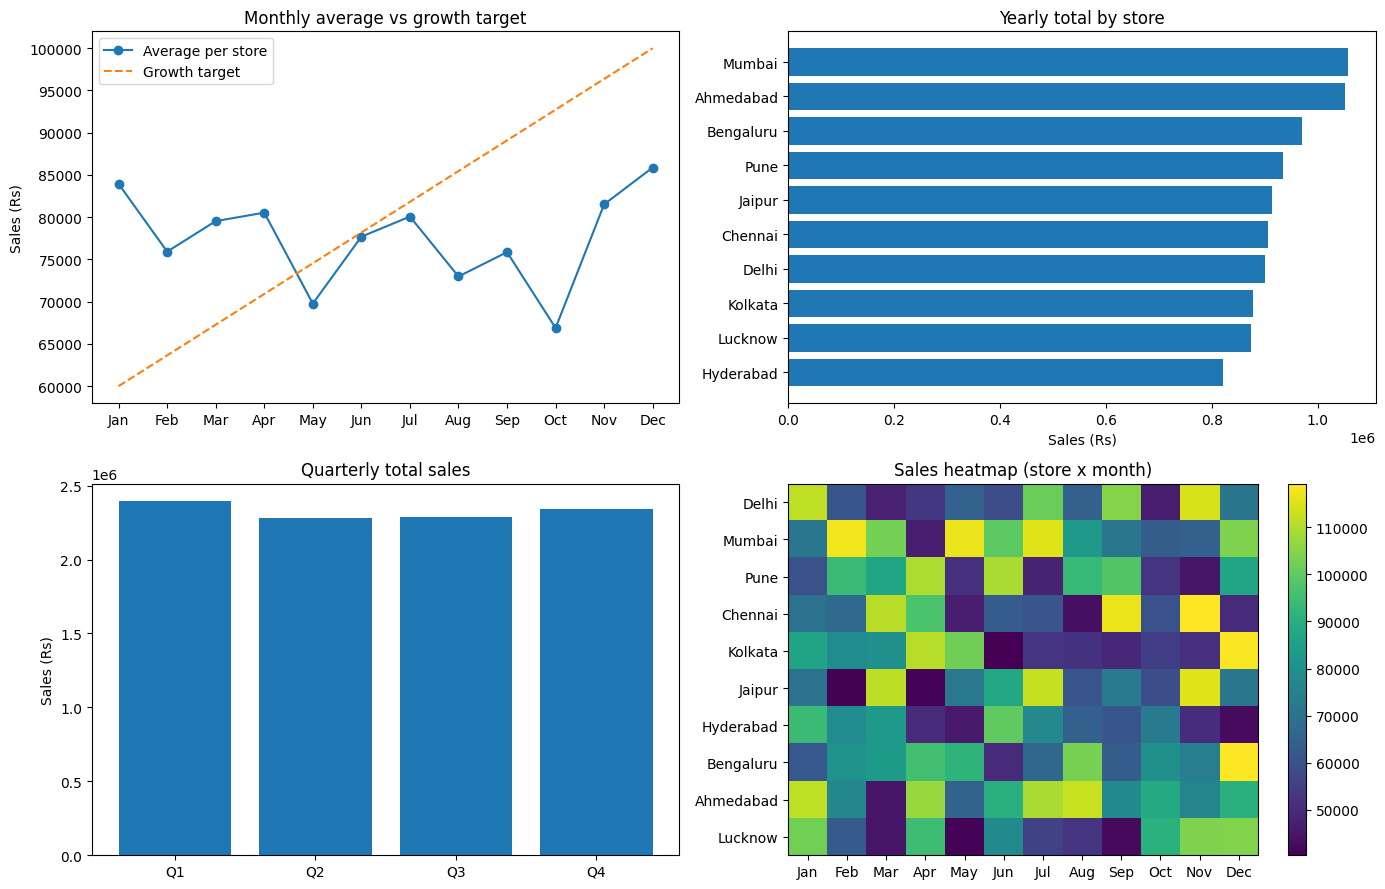

In [22]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 2, figsize=(14, 9))

ax[0, 0].plot(month_names, sales.mean(axis=0), marker="o", label="Average per store")
ax[0, 0].plot(month_names, growth_target, linestyle="--", label="Growth target")
ax[0, 0].set_title("Monthly average vs growth target")
ax[0, 0].set_ylabel("Sales (Rs)")
ax[0, 0].legend()

order = np.argsort(store_total)
ax[0, 1].barh(stores[order], store_total[order])
ax[0, 1].set_title("Yearly total by store")
ax[0, 1].set_xlabel("Sales (Rs)")

ax[1, 0].bar(list(quarters.keys()), [q.sum() for q in quarters.values()])
ax[1, 0].set_title("Quarterly total sales")
ax[1, 0].set_ylabel("Sales (Rs)")

im = ax[1, 1].imshow(sales, aspect="auto")
ax[1, 1].set_xticks(range(12))
ax[1, 1].set_xticklabels(month_names)
ax[1, 1].set_yticks(range(10))
ax[1, 1].set_yticklabels(stores)
ax[1, 1].set_title("Sales heatmap (store x month)")
fig.colorbar(im, ax=ax[1, 1])

plt.tight_layout()
plt.show()

Step 9: Key insights and conclusion



In [23]:
print("KEY INSIGHTS")
print("-" * 50)
print(f"1. Total yearly sales: Rs {sales.sum():,}")
print(f"2. Best store: {stores[store_total.argmax()]} (Rs {store_total.max():,}); "
      f"weakest: {stores[store_total.argmin()]} (Rs {store_total.min():,})")
print(f"3. Best month: {month_names[monthly_total.argmax()]}; weakest month: {month_names[monthly_total.argmin()]}")
print(f"4. Best quarter: {list(quarters)[int(np.argmax([q.sum() for q in quarters.values()]))]}")
print(f"5. Growth target was met in {met_target.mean() * 100:.1f}% of all store-months")
print(f"6. Targets get harder through the year: {met_target[:, :6].mean() * 100:.0f}% hit in H1 "
      f"vs {met_target[:, 6:].mean() * 100:.0f}% in H2")

KEY INSIGHTS
--------------------------------------------------
1. Total yearly sales: Rs 9,305,687
2. Best store: Mumbai (Rs 1,056,911); weakest: Hyderabad (Rs 820,557)
3. Best month: Dec; weakest month: Oct
4. Best quarter: Q1
5. Growth target was met in 45.8% of all store-months
6. Targets get harder through the year: 62% hit in H1 vs 30% in H2
